# 4. Análisis univariado (2.2)

Para cada variable candidata (sin objetivo, identificadores, datos personales ni
variables posteriores al pedido): tipo y cardinalidad, estadísticos, distribución,
asimetría y curtosis, normalidad, atípicos y, en las categóricas, frecuencias y
categorías raras. Solo entrenamiento.

In [1]:
from pathlib import Path
import re, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Markdown, display

project_root = Path.cwd().resolve()
while not (project_root / "_config.yml").exists():
    if project_root.parent == project_root:
        raise FileNotFoundError("No se encontró _config.yml. Ejecuta el notebook dentro de la carpeta del libro.")
    project_root = project_root.parent
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

for _folder in ("tables", "figures"):          # se crean si no existen
    (project_root / _folder).mkdir(exist_ok=True)

from src.project_utils import *

configure_plots()
pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 170)
pd.set_option("display.max_colwidth", 70)
TABLES = project_root / "tables"

def md_out(text):
    display(Markdown(text))

from scipy import stats
train = load_train()
y = train[TARGET]
NUM = ["sales", "order_item_product_price", "order_item_quantity", "order_item_discount", "order_item_discount_rate",
       "order_item_profit_ratio", "benefit_per_order", "sales_per_customer", "days_shipping_scheduled",
       "items_in_order", "orders_prev_7d", "order_hour", "order_dow", "order_month", LAT, LON]
CAT = ["shipping_mode", "payment_type", "market", "order_region", "order_country", "order_state", "order_city",
       "customer_segment", "customer_country", "customer_state", "customer_city", "department_name", "category_name", "product_name"]

## Variables numéricas: estadísticos

In [2]:
est = numeric_summary(train[NUM])
est.to_csv(TABLES / "estadisticas_numericas.csv")
est[["media", "mediana", "desv_est", "p01", "p25", "p75", "p99", "asimetría", "curtosis", "ceros_%", "únicos", "outliers_IQR_%"]].round(3)

,media,mediana,desv_est,p01,p25,p75,p99,asimetría,curtosis,ceros_%,únicos,outliers_IQR_%
sales,196.985,179.970,111.329,29.980,119.980,299.950,499.950,0.658,-0.338,0.000,124,0.000
order_item_product_price,131.294,59.990,117.028,15.990,49.980,199.990,399.980,1.267,0.286,0.000,29,0.000
order_item_quantity,2.204,1.000,1.471,1.000,1.000,3.000,5.000,0.782,-0.915,0.000,5,0.000
order_item_discount,19.974,14.000,19.561,0.000,5.400,28.800,80.000,1.558,2.674,5.556,580,4.440
order_item_discount_rate,0.102,0.100,0.070,0.000,0.040,0.160,0.250,0.341,-0.901,5.556,18,0.000
order_item_profit_ratio,0.120,0.270,0.467,-1.750,0.080,0.360,0.500,-2.886,10.089,0.656,162,9.633
benefit_per_order,21.156,31.120,96.644,-405.870,7.200,63.060,178.463,-3.532,21.697,0.656,18482,10.547
sales_per_customer,177.011,159.990,101.307,25.190,103.990,242.400,424.960,0.706,-0.191,0.000,1951,0.714
days_shipping_scheduled,2.932,4.000,1.374,0.000,2.000,4.000,4.000,-0.732,-1.023,5.390,4,0.000
items_in_order,3.663,4.000,1.243,1.000,3.000,5.000,5.000,-0.590,-0.714,0.000,5,0.000


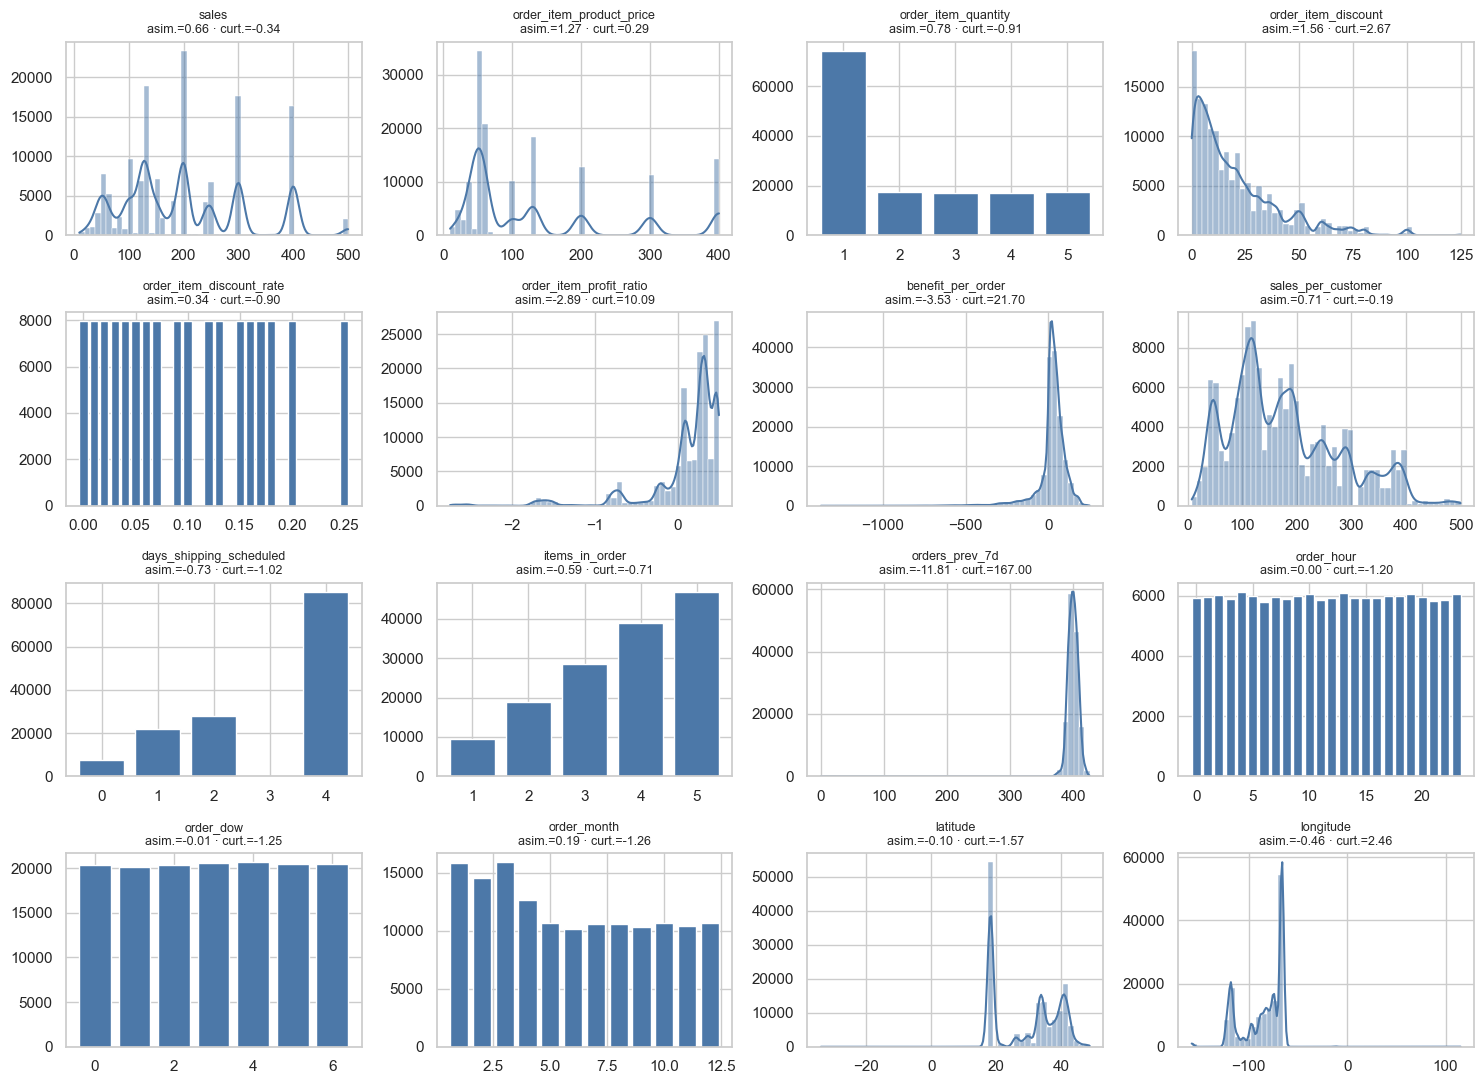

In [3]:
fig, axes = plt.subplots(4, 4, figsize=(15, 11))
for ax, col in zip(axes.ravel(), NUM):
    s = train[col]
    discrete = s.nunique() <= 25
    if discrete:
        vc = s.value_counts().sort_index()
        ax.bar(vc.index.astype(float), vc.values, color="#4c78a8", width=0.8 * (np.diff(vc.index.astype(float)).min() if len(vc) > 1 else 1))
    else:
        sns.histplot(s, bins=50, kde=True, ax=ax, color="#4c78a8")
    ax.set_title(f"{col}\nasim.={s.skew():.2f} · curt.={s.kurt():.2f}", fontsize=9); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); save_figure(fig, "04_histogramas_numericas.png"); plt.show()

**Interpretación.**

- **Precios y ventas** (`sales`, `order_item_product_price`, `sales_per_customer`) son
  discretos (pocos precios distintos) y con **asimetría positiva**: muchos productos de
  bajo precio y unos pocos caros. Se transforman con `log1p` (cap. 10).
- **Ganancia** (`benefit_per_order`, `order_item_profit_ratio`) tiene **cola izquierda
  pesada** (curtosis alta): ventas con pérdidas grandes. Al ser negativa, `log1p` no
  aplica; se escala y se conserva.
- `days_shipping_scheduled` toma solo 4 valores, uno por modo de envío.
- `items_in_order` (1–5) y `order_item_quantity` (1–5) son conteos pequeños.
- Hora, día y mes son **cíclicos**: su distribución es casi uniforme, y se codifican con
  seno y coseno para que 23 h y 0 h queden cerca.
- `orders_prev_7d` es casi constante (≈ 380 pedidos semanales), con una caída en la primera
  semana (no hay historia previa) y un cambio de nivel al final del periodo (cap. 7).
- `latitude`/`longitude` son multimodales: corresponden a ciudades (cap. 8).

## Normalidad y atípicos

Prueba de D'Agostino-Pearson sobre una muestra de 5.000 líneas (con n = 143.000
cualquier desviación mínima resultaría significativa) y gráficos Q-Q.

,variable,K2,p_valor,¿normal al 5 %?
0,sales,323.5969,0.0,no
1,order_item_product_price,832.0994,0.0,no
2,order_item_quantity,1266.1256,0.0,no
3,order_item_discount,1398.9201,0.0,no
4,order_item_discount_rate,834.7984,0.0,no
5,order_item_profit_ratio,3116.9225,0.0,no
6,benefit_per_order,3978.3705,0.0,no
7,sales_per_customer,338.0737,0.0,no
8,days_shipping_scheduled,2259.7550,0.0,no
9,items_in_order,538.7798,0.0,no


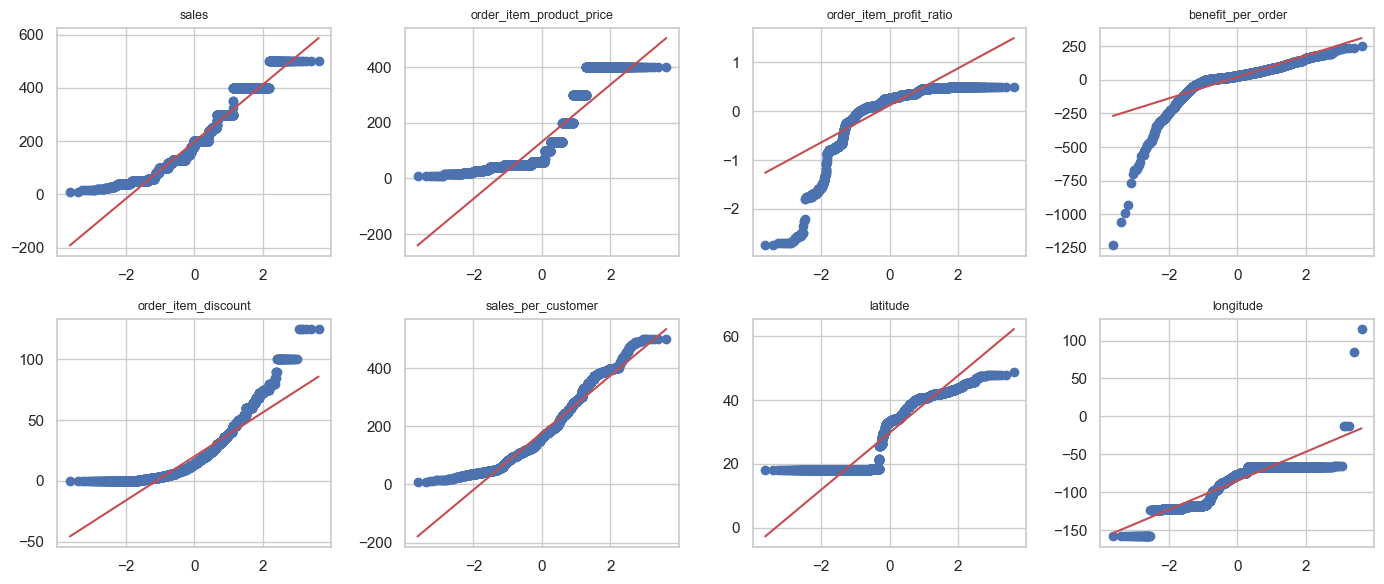

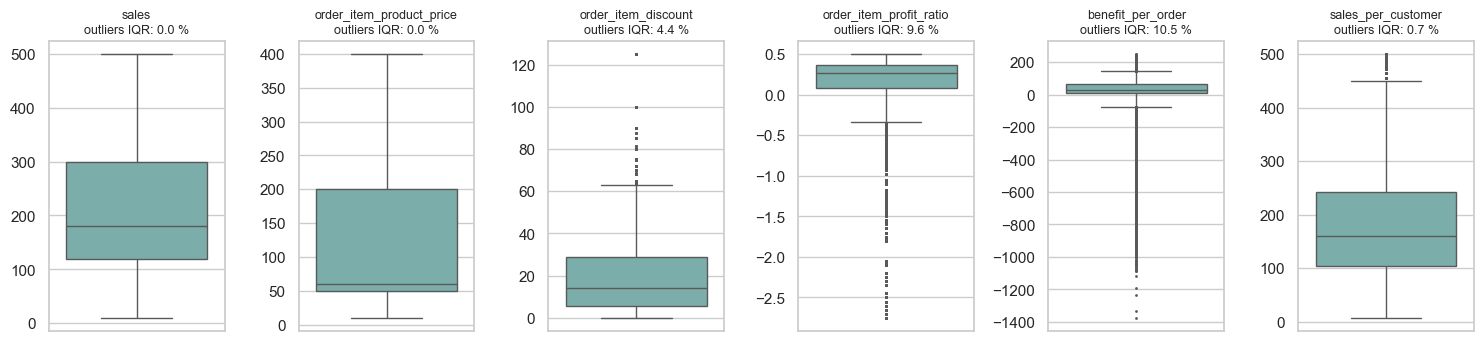

In [4]:
rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(len(train), 5000, replace=False)
norm = []
for col in NUM:
    s = train[col].iloc[idx]
    k2, p = stats.normaltest(s)
    norm.append({"variable": col, "K2": k2, "p_valor": p, "¿normal al 5 %?": "sí" if p > 0.05 else "no"})
norm = pd.DataFrame(norm)
norm.to_csv(TABLES / "normalidad.csv", index=False)
display(norm.round(4))

fig, axes = plt.subplots(2, 4, figsize=(14, 6))
for ax, col in zip(axes.ravel(), ["sales", "order_item_product_price", "order_item_profit_ratio", "benefit_per_order",
                                  "order_item_discount", "sales_per_customer", LAT, LON]):
    stats.probplot(train[col].iloc[idx], dist="norm", plot=ax)
    ax.set_title(col, fontsize=9); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); save_figure(fig, "04_qqplots.png"); plt.show()

cont = ["sales", "order_item_product_price", "order_item_discount", "order_item_profit_ratio", "benefit_per_order", "sales_per_customer"]
fig, axes = plt.subplots(1, len(cont), figsize=(15, 3.6))
for ax, col in zip(axes, cont):
    sns.boxplot(y=train[col], ax=ax, color="#72b7b2", fliersize=1)
    ax.set_title(f"{col}\noutliers IQR: {est.loc[col, 'outliers_IQR_%']:.1f} %", fontsize=9); ax.set_ylabel("")
plt.tight_layout(); save_figure(fig, "04_boxplots.png"); plt.show()

**Interpretación.** Ninguna variable es normal (era esperable: son precios,
conteos y coordenadas). La normalidad **no es requisito** de la regresión logística;
la transformación logarítmica se aplica para reducir la influencia de la cola, no
para normalizar. Los atípicos por IQR se concentran en la ganancia (≈ 10 %), y
corresponden a ventas con pérdida, no a errores (capítulo 2): se **conservan**.

## Variables categóricas: cardinalidad, frecuencias y categorías raras

,variable,cardinalidad,moda,frecuencia_moda_%,"categorías_raras_<0,5%",líneas_en_raras_%
0,shipping_mode,4,Standard Class,59.67,0,0.00
1,payment_type,4,DEBIT,38.46,0,0.00
2,market,5,LATAM,28.43,0,0.00
3,order_region,23,Central America,15.57,1,0.39
4,order_country,164,Estados Unidos,17.36,125,12.36
5,order_state,1089,California,3.47,1055,62.63
6,order_city,3553,New York City,1.54,3535,85.35
7,customer_segment,3,Consumer,51.80,0,0.00
8,customer_country,2,EE. UU.,61.74,0,0.00
9,customer_state,44,PR,38.26,18,3.84


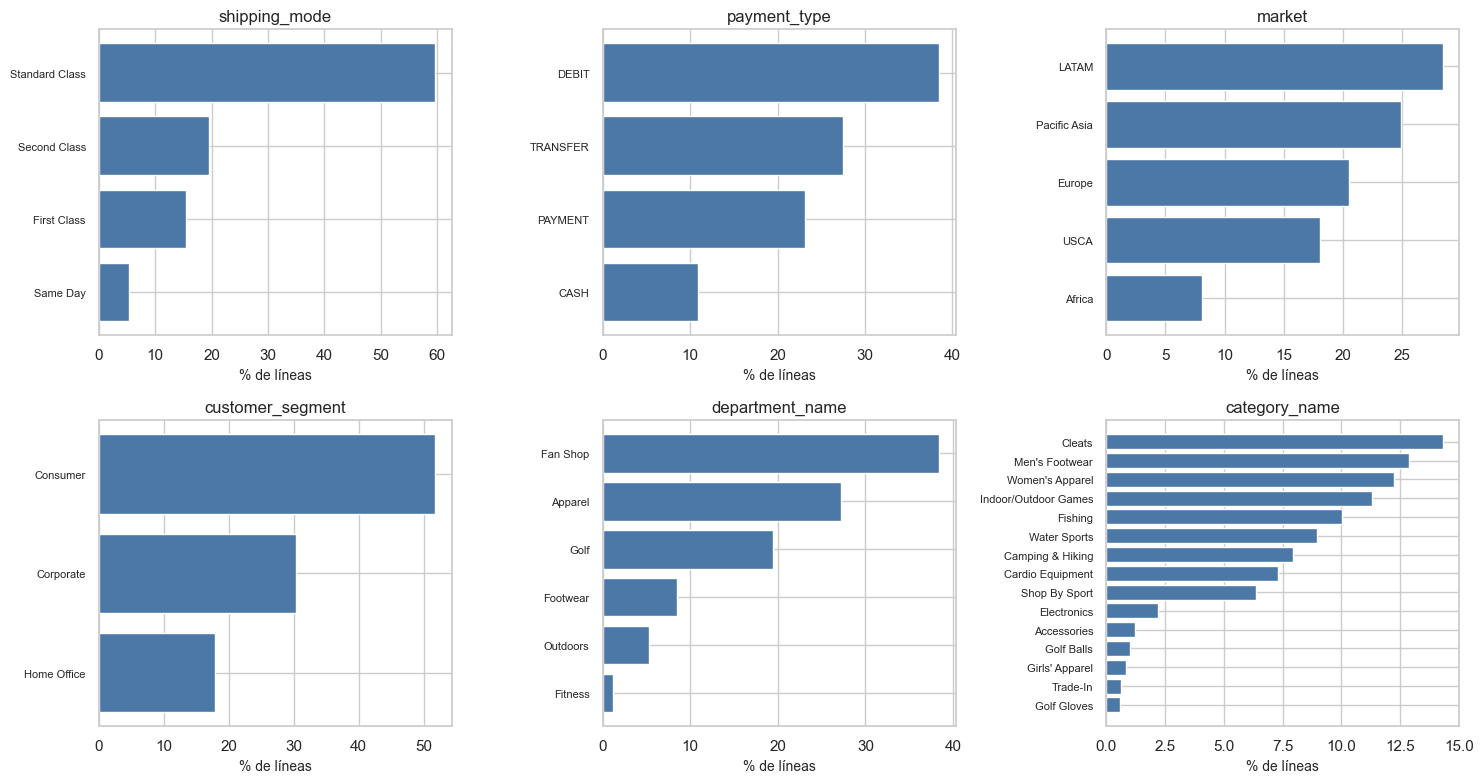

In [5]:
filas = []
for col in CAT:
    vc = train[col].value_counts(normalize=True)
    filas.append({"variable": col, "cardinalidad": train[col].nunique(), "moda": vc.index[0], "frecuencia_moda_%": 100 * vc.iloc[0],
                  "categorías_raras_<0,5%": int((vc < 0.005).sum()), "líneas_en_raras_%": 100 * vc[vc < 0.005].sum()})
res_cat = pd.DataFrame(filas)
res_cat.to_csv(TABLES / "resumen_categoricas.csv", index=False)
display(res_cat.round(2))

fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, col in zip(axes.ravel(), ["shipping_mode", "payment_type", "market", "customer_segment", "department_name", "category_name"]):
    vc = train[col].value_counts().head(15).iloc[::-1]
    ax.barh(vc.index, 100 * vc.values / len(train), color="#4c78a8")
    ax.set_title(col); ax.set_xlabel("% de líneas"); ax.tick_params(axis="y", labelsize=8)
plt.tight_layout(); save_figure(fig, "04_categoricas.png"); plt.show()

**Interpretación y tratamiento de categorías raras.**

- `shipping_mode`: Standard Class domina (≈ 60 %); Same Day es la más rara (≈ 5 %), pero
  con miles de casos.
- `payment_type`, `market`, `customer_segment` y `department_name` tienen pocas
  categorías y ninguna rara.
- `order_country` (≈ 160), `order_state`, `order_city`, `customer_city` y `product_name`
  tienen **alta cardinalidad** y muchas categorías raras. Codificarlas tal cual crearía
  cientos de columnas con pocos casos (sobreajuste). **Tratamiento:** en el Pipeline,
  `OneHotEncoder(min_frequency=0.005, handle_unknown="infrequent_if_exist")` agrupa en
  «infrequent» las categorías con < 0,5 % de líneas **calculadas solo en entrenamiento**,
  y las categorías nuevas de la prueba caen en ese mismo grupo. Las de ciudad se descartan
  (la región y el país ya capturan la geografía, cap. 5).
- `customer_country` solo tiene EE. UU. y Puerto Rico (sesgo de muestreo, cap. 2).